<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/kalman/notebooks/kalman_produto_de_gaussianas_faragher.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

*O Filtro de Kalman para Cientistas da Computação* · [← guia da série](kalman_guia_da_serie.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/kalman/notebooks/kalman_guia_da_serie.ipynb)) · [repositório](https://github.com/saulobortolon/Quaternios-Kalman-CC) · série irmã: [*Números, movimento e Kalman*](../../dominios/notebooks/X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb))

# O Filtro de Kalman como produto de gaussianas
## Acompanhando, passo a passo, as *lecture notes* de Faragher (2012)

**Texto acompanhado.** R. Faragher, "Understanding the Basis of the Kalman Filter Via a Simple and Intuitive Derivation", *IEEE Signal Processing Magazine*, 29(5):128–132, setembro de 2012. DOI: 10.1109/MSP.2012.2203621.

Este notebook **segue a ordem e o exemplo do artigo** (um trem num trilho), mas com texto próprio. Recomenda-se ler o artigo ao lado: aqui cada equação vira código, cada figura é refeita e cada afirmação é conferida numericamente. No fim, a seção 8 reúne as notas críticas, e a seção 7 vai além do artigo, mostrando o que a dedução escalar não consegue mostrar.

**A ideia do artigo, numa frase.** Na atualização, o Kalman **multiplica** a gaussiana da previsão pela gaussiana da medida; como o produto de duas gaussianas é (proporcional a) outra gaussiana, a crença nunca fica mais complicada, e o filtro pode seguir indefinidamente.

**Lugar na série.** Leitura introdutória ao notebook `kalman_passo_a_passo` (cujos quadros mostram exatamente esse produto de gaussianas), e complemento das seções A1–A3 e C1 de `mq_hmm_kalman_duas_trilhas`.

**Roteiro**
1. O problema: o trem, o controle e a medida
2. A predição: de onde vem $P^-=FPF^\top+Q$
3. As figuras do artigo: *prior*, predição, medida, fusão
4. O produto de duas gaussianas (e a constante que o artigo não mostra)
5. Medida em outro domínio: o tempo de voo e o aparecimento de $H$
6. Das fórmulas escalares às matriciais
7. Além do artigo: medir a posição e aprender a velocidade
8. Notas críticas
9. Exercícios

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=False)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(2012)

def confere(nome, a, b, tol=1e-8, relativo=False):
    a, b = np.asarray(a, float), np.asarray(b, float)
    erro = np.max(np.abs(a - b)) / (np.max(np.abs(b)) if relativo else 1.0)
    print(f"{'OK ' if erro < tol else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert erro < tol, nome

def gauss(x, mu, var):
    return np.exp(-0.5 * (x - mu)**2 / var) / np.sqrt(2 * np.pi * var)

---
# 1. O problema: o trem, o controle e a medida

Um trem anda num trilho reto. O estado tem duas componentes, **posição** $x_t$ e **velocidade** $\dot x_t$. O maquinista acelera ou freia: a força $f_t$ do motor ou do freio, dividida pela massa $m$, é uma **aceleração conhecida**, a **entrada de controle** $u_t=f_t/m$.

Se a aceleração é constante durante um intervalo $\Delta t$, a física de colégio dá

$$x_t=x_{t-1}+\dot x_{t-1}\,\Delta t+\tfrac12 u_t\,\Delta t^2,\qquad \dot x_t=\dot x_{t-1}+u_t\,\Delta t,$$

ou, em forma matricial (eq. 1 do artigo),

$$\underbrace{\begin{bmatrix}x_t\\ \dot x_t\end{bmatrix}}_{x_t}=\underbrace{\begin{bmatrix}1&\Delta t\\0&1\end{bmatrix}}_{F}\begin{bmatrix}x_{t-1}\\ \dot x_{t-1}\end{bmatrix}+\underbrace{\begin{bmatrix}\Delta t^2/2\\ \Delta t\end{bmatrix}}_{B}u_t+w_t .$$

**A novidade em relação ao resto da série é o termo $Bu_t$.** Até agora, tudo o que fazia o estado mudar era desconhecido e ia para o ruído $w_t$. Aqui, parte da mudança é **conhecida**: o filtro sabe que o maquinista acelerou. O ruído $w_t$ fica só com o que **não** se sabe. Neste notebook, $w_t$ vem de uma aceleração extra desconhecida $a_t\sim\mathcal N(0,\sigma_a^2)$ (rajadas de vento, inclinação do trilho, atrito), e por isso

$$w_t=B\,a_t\quad\Longrightarrow\quad Q=\mathrm{Cov}(w_t)=\sigma_a^2\,BB^\top .$$

**A medida.** Um transmissor de rádio na origem do trilho mede o **tempo de voo** do sinal até a antena do trem, $s_t=x_t/c+v_t$, com $c$ a velocidade da luz. O artigo trata primeiro uma versão simplificada, em que a medida já vem em metros, e só depois introduz o tempo de voo (seção 5).

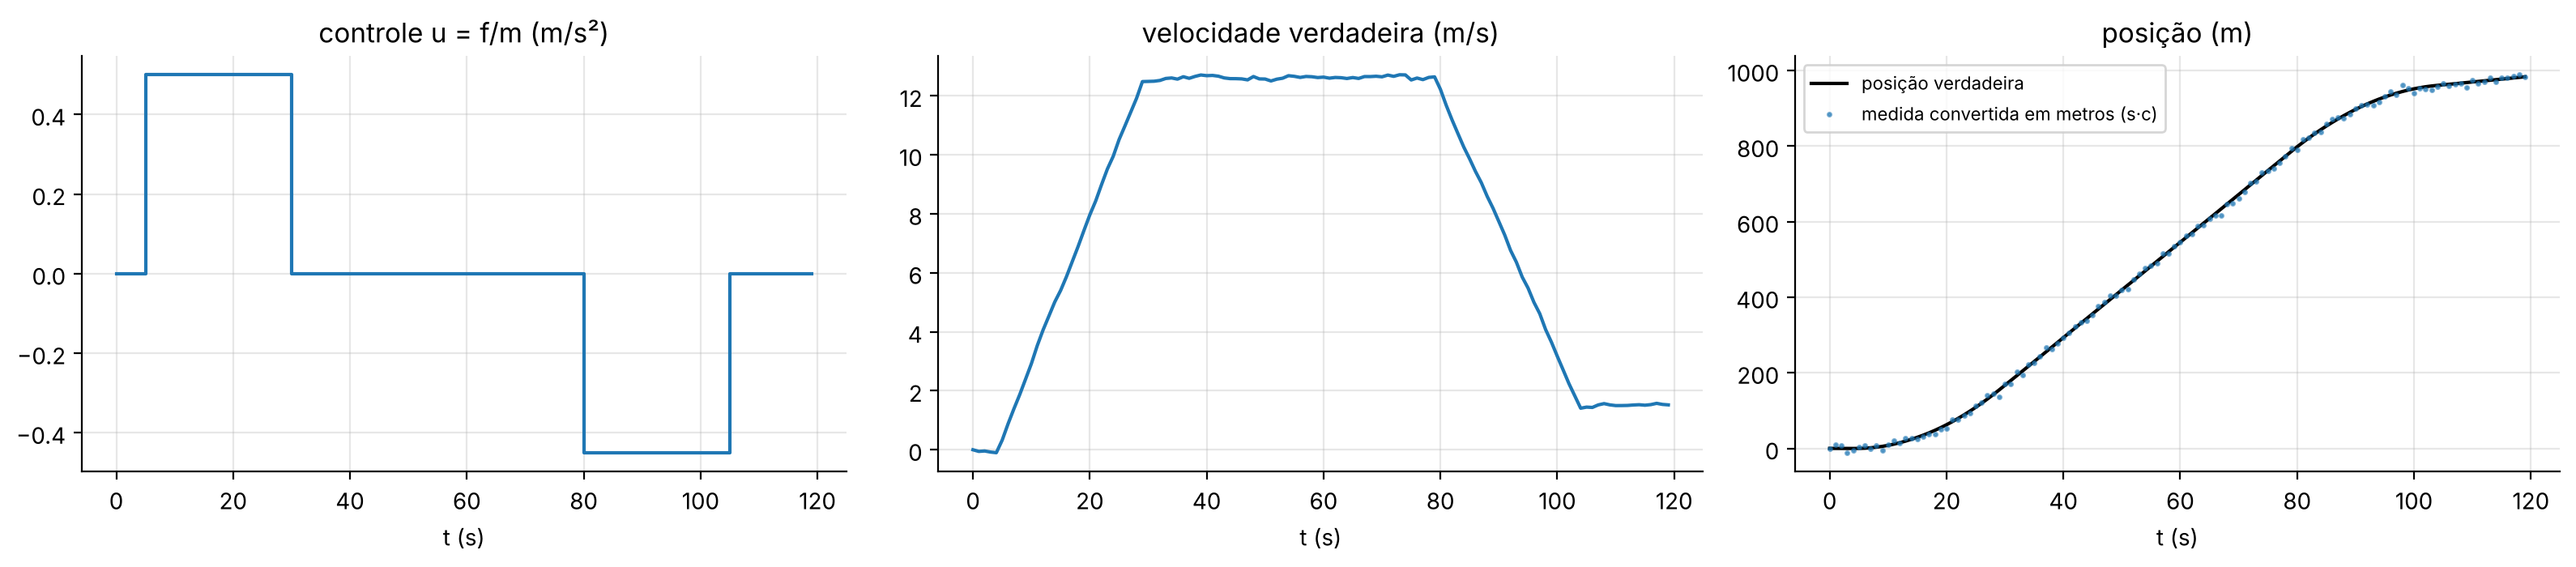

F =
 [[1. 1.]
 [0. 1.]] 
B = [0.5 1. ] 
Q = σ_a² B Bᵀ =
 [[0.0006 0.0013]
 [0.0013 0.0025]]


In [2]:
DT = 1.0                                   # s
F = np.array([[1.0, DT], [0.0, 1.0]])
B = np.array([[DT**2 / 2], [DT]])
SIG_A = 0.05                               # m/s²: aceleração desconhecida (desvio-padrão)
Q = SIG_A**2 * (B @ B.T)
C_LUZ = 3.0e8                              # m/s
SIG_S = 2.0e-8                             # s: erro do relógio do tempo de voo (≈ 6 m)

# perfil de controle do maquinista: acelera, mantém, freia
T = 120
u = np.zeros(T); u[5:30] = 0.5; u[80:105] = -0.45      # m/s²

x_verd = np.zeros((T, 2)); x_verd[0] = [0.0, 0.0]
for t in range(1, T):
    a_desconhecida = SIG_A * rng.standard_normal()
    x_verd[t] = F @ x_verd[t - 1] + (B * (u[t] + a_desconhecida)).ravel()
s_med = x_verd[:, 0] / C_LUZ + SIG_S * rng.standard_normal(T)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].step(range(T), u, where="post"); ax[0].set_title("controle u = f/m (m/s²)"); ax[0].set_xlabel("t (s)")
ax[1].plot(x_verd[:, 1]); ax[1].set_title("velocidade verdadeira (m/s)"); ax[1].set_xlabel("t (s)")
ax[2].plot(x_verd[:, 0], "k", label="posição verdadeira")
ax[2].plot(s_med * C_LUZ, ".", ms=3, alpha=.6, label="medida convertida em metros (s·c)")
ax[2].set_title("posição (m)"); ax[2].set_xlabel("t (s)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("F =\n", F, "\nB =", B.ravel(), "\nQ = σ_a² B Bᵀ =\n", Q)

**Detalhes do código.**

- **`B * (u[t] + a_desconhecida)`**: a aceleração real é a comandada **mais** a desconhecida, e as duas entram pelo mesmo caminho $B$.
- **`.ravel()`**: `B` é uma matriz $2\times1$, e `.ravel()` a transforma num vetor de tamanho 2 para somar ao estado.
- **Ordem de grandeza da medida:** um erro de $2\times10^{-8}$ s no relógio equivale a $c\cdot 2\times10^{-8}\approx 6$ m de posição.

---
# 2. A predição: de onde vem $P^-=FPF^\top+Q$

A predição é a eq. (3) do artigo: aplicar o modelo à melhor estimativa, $\hat x_{t|t-1}=F\hat x_{t-1|t-1}+Bu_t$. O controle **conhecido** entra na média e **não** mexe na incerteza.

Para a covariância, eq. (4), o artigo subtrai a predição do modelo verdadeiro:

$$x_t-\hat x_{t|t-1}=F\,(x_{t-1}-\hat x_{t-1|t-1})+w_t .$$

O erro novo é o erro antigo transportado por $F$, mais o ruído. Calculando a covariância dos dois lados, e usando que o erro antigo e o ruído novo são **independentes** (os termos cruzados têm média zero),

$$P_{t|t-1}=F\,P_{t-1|t-1}\,F^\top+Q .$$

**Conferência por Monte Carlo.** Sorteamos 200 000 erros com covariância $P$, aplicamos a equação do erro e medimos a covariância amostral.

In [3]:
P_ant = np.array([[4.0, 0.6], [0.6, 0.25]])
N_MC = 200_000
L = np.linalg.cholesky(P_ant)
erros_ant = rng.standard_normal((N_MC, 2)) @ L.T                       # erros com covariância P_ant
ruidos = (B @ (SIG_A * rng.standard_normal((1, N_MC)))).T              # w = B·a
erros_novos = erros_ant @ F.T + ruidos
print("covariância amostral dos erros previstos:\n", np.cov(erros_novos.T))
print("F P Fᵀ + Q:\n", F @ P_ant @ F.T + Q)
confere("F P Fᵀ + Q = covariância do erro previsto (Monte Carlo)", np.cov(erros_novos.T), F @ P_ant @ F.T + Q,
        tol=2e-2, relativo=True)

covariância amostral dos erros previstos:
 [[5.4499 0.8496]
 [0.8496 0.2521]]
F P Fᵀ + Q:
 [[5.4506 0.8512]
 [0.8512 0.2525]]
OK   F P Fᵀ + Q = covariância do erro previsto (Monte Carlo):  diferença relativa máxima = 2.95e-04


A tolerância é de 2%, a precisão possível com 200 000 amostras. Repare que o termo $FPF^\top$ cria **correlação** entre posição e velocidade, mesmo que $P$ não tivesse nenhuma. Se a velocidade estava errada para mais, a posição prevista também estará. Guarde isso para a seção 7.

---
# 3. As figuras do artigo: *prior*, predição, medida, fusão

O artigo conta a atualização em quatro figuras, todas só com a **posição** do trem. Refazemos as quatro com números concretos:

- **(Fig. 2)** Em $t=0$, a posição é conhecida com alguma incerteza: $\mathcal N(0,\ 2^2)$ m. A velocidade, 10 m/s, é conhecida.
- **(Fig. 3)** Em $t=1$ s, a predição desloca a crença 10 m para a frente e a **alarga**, porque o trem pode ter acelerado ou freado sem que saibamos.
- **(Fig. 4)** Chega uma medida ruidosa de posição: $z=13$ m, com desvio-padrão de 3 m.
- **(Fig. 5)** A melhor crença combina as duas: é o **produto** das duas curvas, normalizado.

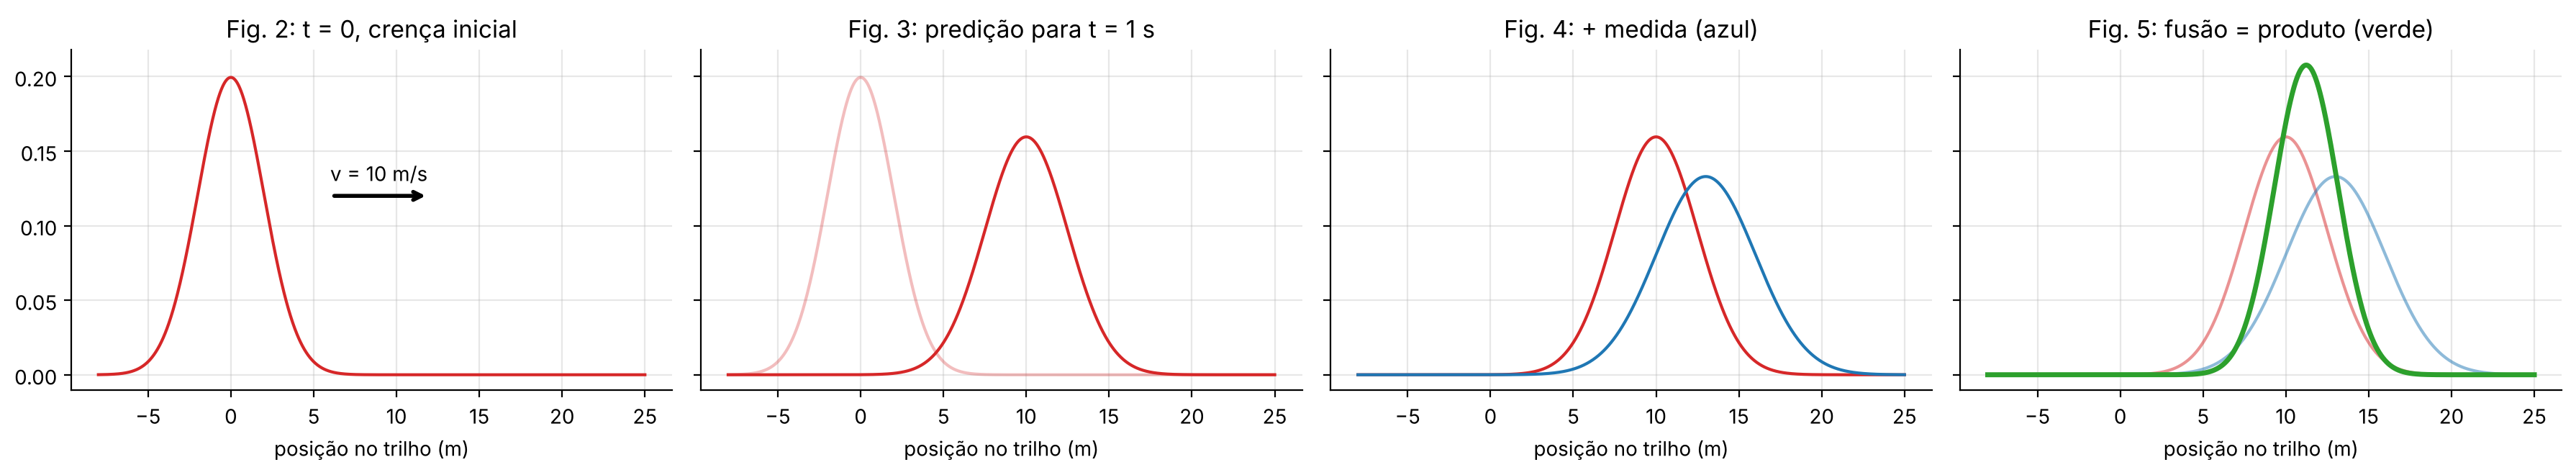

predição: média 10.00, desvio 2.50 | medida: 13.00, desvio 3.00 | fusão: média 11.23, desvio 1.92


In [4]:
mu0, var0, v0 = 0.0, 2.0**2, 10.0
var_acel = 1.5**2                          # incerteza acrescentada pela aceleração desconhecida em 1 s
mu1, var1 = mu0 + v0 * 1.0, var0 + var_acel
mu2, var2 = 13.0, 3.0**2
var_f = var1 * var2 / (var1 + var2)
mu_f = (mu1 * var2 + mu2 * var1) / (var1 + var2)

r = np.linspace(-8, 25, 1500)
fig, ax = plt.subplots(1, 4, figsize=(18, 3.4), sharey=True)
ax[0].plot(r, gauss(r, mu0, var0), "C3"); ax[0].set_title("Fig. 2: t = 0, crença inicial")
ax[0].annotate("", xy=(12, .12), xytext=(6, .12), arrowprops=dict(arrowstyle="->", lw=2)); ax[0].text(6, .13, "v = 10 m/s")
ax[1].plot(r, gauss(r, mu0, var0), "C3", alpha=.3); ax[1].plot(r, gauss(r, mu1, var1), "C3")
ax[1].set_title("Fig. 3: predição para t = 1 s")
ax[2].plot(r, gauss(r, mu1, var1), "C3"); ax[2].plot(r, gauss(r, mu2, var2), "C0"); ax[2].set_title("Fig. 4: + medida (azul)")
ax[3].plot(r, gauss(r, mu1, var1), "C3", alpha=.5); ax[3].plot(r, gauss(r, mu2, var2), "C0", alpha=.5)
ax[3].plot(r, gauss(r, mu_f, var_f), "C2", lw=2.5); ax[3].set_title("Fig. 5: fusão = produto (verde)")
for a in ax: a.set_xlabel("posição no trilho (m)")
plt.tight_layout(); plt.show()
print(f"predição: média {mu1:.2f}, desvio {np.sqrt(var1):.2f} | medida: {mu2:.2f}, desvio {np.sqrt(var2):.2f} | "
      f"fusão: média {mu_f:.2f}, desvio {np.sqrt(var_f):.2f}")

**O que observar.** A curva verde fica **entre** as outras duas, mais perto da mais estreita (a predição, com desvio 2,5 m, contra 3 m da medida). E é **mais estreita que as duas**: juntar duas fontes de informação independentes sempre reduz a incerteza.

---
# 4. O produto de duas gaussianas

## 4.1 As fórmulas do artigo

O artigo multiplica

$$y_1(r)=\mathcal N(r;\mu_1,\sigma_1^2)\quad\text{(predição)}\qquad\text{e}\qquad y_2(r)=\mathcal N(r;\mu_2,\sigma_2^2)\quad\text{(medida)},$$

completa o quadrado no expoente e reconhece outra gaussiana, com (eqs. 12 e 13)

$$\mu=\mu_1+\frac{\sigma_1^2}{\sigma_1^2+\sigma_2^2}\,(\mu_2-\mu_1),\qquad \sigma^2=\sigma_1^2-\frac{\sigma_1^4}{\sigma_1^2+\sigma_2^2}=\frac{\sigma_1^2\sigma_2^2}{\sigma_1^2+\sigma_2^2}.$$

A fração $\sigma_1^2/(\sigma_1^2+\sigma_2^2)$ já é o **ganho de Kalman** escalar.

Duas formas equivalentes ajudam a entender:

- **As precisões se somam:** $\dfrac1{\sigma^2}=\dfrac1{\sigma_1^2}+\dfrac1{\sigma_2^2}$.
- **A média é ponderada pelas precisões:** $\mu=\dfrac{\mu_1/\sigma_1^2+\mu_2/\sigma_2^2}{1/\sigma_1^2+1/\sigma_2^2}$.

## 4.2 A constante que o artigo não mostra

O produto de duas **densidades** não é uma densidade: a área sob $y_1y_2$ não é 1. O resultado é uma gaussiana **multiplicada por uma constante**,

$$y_1(r)\,y_2(r)=\underbrace{\mathcal N\big(\mu_2;\ \mu_1,\ \sigma_1^2+\sigma_2^2\big)}_{Z}\ \cdot\ \mathcal N(r;\mu,\sigma^2).$$

A constante $Z$ não é um detalhe. Ela é a **densidade da medida que foi efetivamente observada**, segundo a predição: a verossimilhança da inovação $\mu_2-\mu_1$, com covariância $S=\sigma_1^2+\sigma_2^2$. É o termo `ll` da função `kf_atualizacao` do notebook *passo a passo*, o que permite estimar $Q$ e $R$ por máxima verossimilhança, e o que pesa os modos no IMM da Parte 2 do Pepé.

Conferimos tudo numa grade fina: integramos o produto, normalizamos e comparamos com as fórmulas.

In [5]:
r = np.linspace(-60, 80, 400_001); dr = r[1] - r[0]
produto = gauss(r, mu1, var1) * gauss(r, mu2, var2)
Z_numerico = produto.sum() * dr
media_num = (r * produto).sum() * dr / Z_numerico
var_num = ((r - media_num)**2 * produto).sum() * dr / Z_numerico

confere("média do produto = eq. (12)", media_num, mu_f, tol=1e-6)
confere("variância do produto = eq. (13)", var_num, var_f, tol=1e-6)
confere("as precisões se somam", 1 / var_f, 1 / var1 + 1 / var2, tol=1e-12)
confere("o produto normalizado é a gaussiana N(μ, σ²)", produto / Z_numerico, gauss(r, mu_f, var_f), tol=1e-6)
confere("a área do produto é Z = N(μ₂; μ₁, σ₁² + σ₂²), a verossimilhança da inovação",
        Z_numerico, gauss(mu2, mu1, var1 + var2), tol=1e-9)
print(f"\nZ = {Z_numerico:.5f}:  a área de y₁·y₂ não é 1")

OK   média do produto = eq. (12):  diferença máxima = 0.00e+00
OK   variância do produto = eq. (13):  diferença máxima = 4.44e-16
OK   as precisões se somam:  diferença máxima = 5.55e-17
OK   o produto normalizado é a gaussiana N(μ, σ²):  diferença máxima = 1.54e-12
OK   a área do produto é Z = N(μ₂; μ₁, σ₁² + σ₂²), a verossimilhança da inovação:  diferença máxima = 5.63e-13

Z = 0.07605:  a área de y₁·y₂ não é 1


**Por que multiplicar?** O artigo apresenta o produto como uma maneira natural de "juntar informação", sem justificar. A justificativa é a **regra de Bayes**:

$$\underbrace{p(x\mid z)}_{\text{posterior}}=\frac{\overbrace{p(z\mid x)}^{\text{verossimilhança}}\ \overbrace{p(x)}^{\text{prior (predição)}}}{\underbrace{p(z)}_{=Z}} .$$

A curva azul do artigo não é a densidade da posição do trem; é a **verossimilhança** $p(z\mid x)$ vista como função de $x$. No caso escalar com $H=1$, as duas coisas têm a mesma forma, e a distinção passa despercebida. Com $H\neq1$ (seção 5) e com estado vetorial (seção 7), ela passa a importar.

---
# 5. Medida em outro domínio: o tempo de voo e o aparecimento de $H$

Agora a medida é o tempo de voo $s=x/c+v$, em **segundos**, enquanto a predição está em **metros**. Para multiplicar as duas curvas, elas têm de estar no mesmo eixo. O artigo leva a predição para o domínio da medida: $x\sim\mathcal N(\mu_1,\sigma_1^2)$ implica $x/c\sim\mathcal N(\mu_1/c,\ \sigma_1^2/c^2)$. Funde as duas curvas lá, com as fórmulas da seção 4, e volta multiplicando por $c$.

Fazendo as contas e chamando $H=1/c$, aparece (eqs. 16–18)

$$\mu=\mu_1+K\,(z-H\mu_1),\qquad \sigma^2=\sigma_1^2-K H\sigma_1^2,\qquad K=\frac{H\sigma_1^2}{H^2\sigma_1^2+\sigma_2^2},$$

que são as equações do Kalman com uma matriz de observação $H$.

Conferimos com o primeiro passo do trem: fusão no domínio do tempo, com volta para metros, comparada com a fórmula do Kalman com $H=1/c$.

In [6]:
H_esc = 1 / C_LUZ
mu1_m, var1_m = 120.0, 15.0**2                     # predição em metros
z_s, var2_s = 125.0 / C_LUZ, SIG_S**2              # medida em segundos

# (a) receita do artigo: leva a predição para segundos, funde lá, volta para metros
mu1_s, var1_s = mu1_m / C_LUZ, var1_m / C_LUZ**2
mu_fs = mu1_s + var1_s / (var1_s + var2_s) * (z_s - mu1_s)
var_fs = var1_s * var2_s / (var1_s + var2_s)
mu_receita, var_receita = mu_fs * C_LUZ, var_fs * C_LUZ**2

# (b) Kalman com H = 1/c, direto em metros
K_esc = H_esc * var1_m / (H_esc**2 * var1_m + var2_s)
mu_kalman, var_kalman = mu1_m + K_esc * (z_s - H_esc * mu1_m), var1_m - K_esc * H_esc * var1_m

confere("fundir no domínio da medida e voltar = Kalman com H = 1/c (média)", mu_receita, mu_kalman, tol=1e-9)
confere("idem (variância)", var_receita, var_kalman, tol=1e-9)
print(f"K = {K_esc:.4e} m/s  (unidade de K: metros de correção por segundo de inovação)")

OK   fundir no domínio da medida e voltar = Kalman com H = 1/c (média):  diferença máxima = 0.00e+00
OK   idem (variância):  diferença máxima = 7.11e-15
K = 2.5862e+08 m/s  (unidade de K: metros de correção por segundo de inovação)


**Atenção ao limite dessa receita.** Ela funciona porque $H=1/c$ é um número que pode ser **invertido**: dá para ir dos segundos aos metros e voltar. Mas no próprio trem o estado tem duas componentes e a medida, uma: a matriz de observação completa é

$$H=\begin{bmatrix}1/c & 0\end{bmatrix},$$

que **não tem inversa**. Não existe uma maneira de "levar a medida para o domínio do estado", porque ela nada diz sobre a velocidade. A fórmula $K=PH^\top(HPH^\top+R)^{-1}$ continua funcionando nesse caso; a receita de converter e voltar, não. É o assunto da seção 7.

---
# 6. Das fórmulas escalares às matriciais

O artigo termina associando cada símbolo escalar a uma matriz:

| escalar (seções 4 e 5) | matricial (eqs. 5–7) | significado |
|---|---|---|
| $\mu_1$ | $\hat x_{t\mid t-1}$ | estado previsto |
| $\sigma_1^2$ | $P_{t\mid t-1}$ | covariância prevista |
| $\mu_2$ | $z_t$ | medida |
| $\sigma_2^2$ | $R_t$ | covariância do ruído de medida |
| $H$ | $H_t$ | leva o estado para o domínio da medida |
| $\dfrac{H\sigma_1^2}{H^2\sigma_1^2+\sigma_2^2}$ | $K_t=P_{t\mid t-1}H_t^\top\big(H_tP_{t\mid t-1}H_t^\top+R_t\big)^{-1}$ | ganho de Kalman |
| $\mu=\mu_1+K(\mu_2-H\mu_1)$ | $\hat x_{t\mid t}=\hat x_{t\mid t-1}+K_t(z_t-H_t\hat x_{t\mid t-1})$ | correção |
| $\sigma^2=\sigma_1^2-KH\sigma_1^2$ | $P_{t\mid t}=P_{t\mid t-1}-K_tH_tP_{t\mid t-1}$ | covariância corrigida |

A tabela é uma boa **mnemônica**, mas não é uma **dedução**: o caso escalar não tem como mostrar o que acontece fora da diagonal de $P$. Para isso, é preciso fazer a conta em mais de uma dimensão.

---
# 7. Além do artigo: medir a posição e aprender a velocidade

## 7.1 O produto de gaussianas em duas dimensões

A ideia do artigo vale em qualquer dimensão: a posterior é o *prior* vezes a verossimilhança, normalizado. Só que agora o *prior* é uma gaussiana em duas dimensões (posição, velocidade), com covariância $P^-$, e a verossimilhança de uma medida de posição **não depende da velocidade**. Ela é uma **faixa** no plano posição × velocidade: estreita na direção da posição, infinita na direção da velocidade.

O produto de uma elipse **inclinada** (o *prior*, com posição e velocidade correlacionadas) por uma faixa **vertical** (a medida) é uma elipse menor, cujo centro se move **também na direção da velocidade**. É assim que medir só a posição corrige a velocidade.

Conferimos numa grade: os momentos do produto, calculados numericamente, coincidem com a atualização de Kalman com $H=[1/c\;\;0]$.

OK   média do produto 2D (grade) = atualização de Kalman:  diferença relativa máxima = 1.95e-16
OK   covariância do produto 2D (grade) = atualização de Kalman:  diferença relativa máxima = 1.04e-13


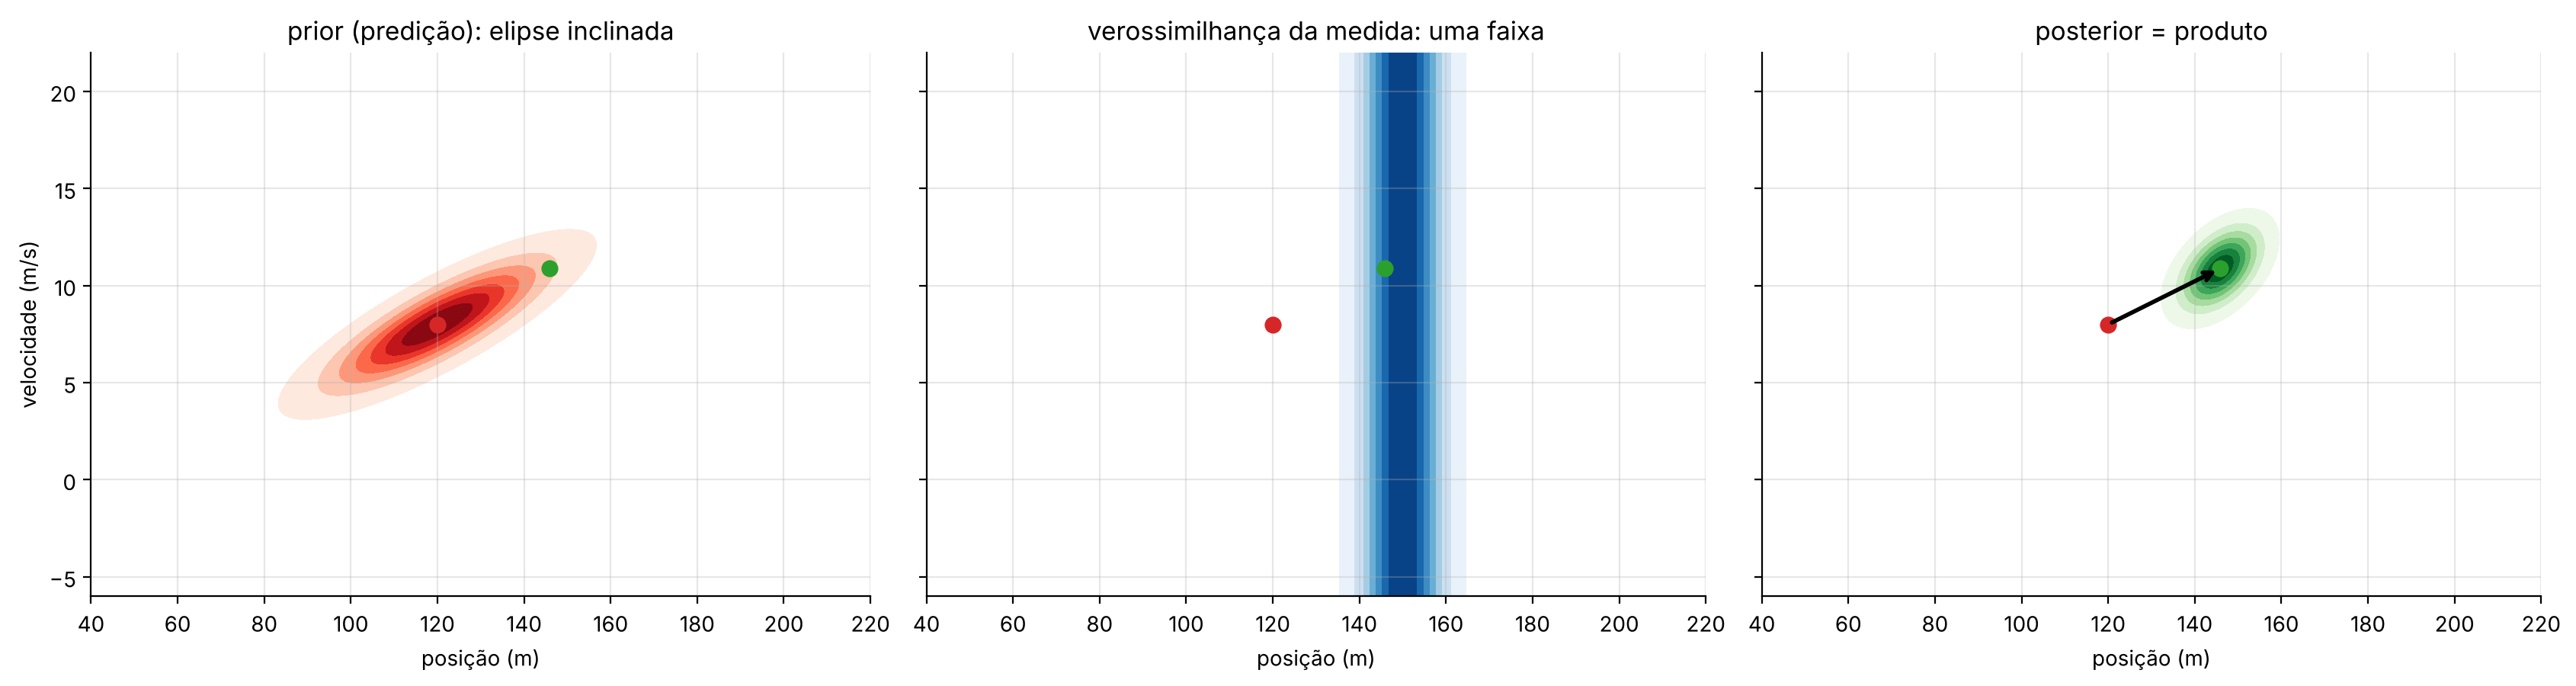

a medida disse 'posição 150 m'.  posição: 120.0 → 145.9 m;   velocidade: 8.00 → 10.87 m/s


In [7]:
m_pri = np.array([120.0, 8.0])                         # predição: posição 120 m, velocidade 8 m/s
P_pri = np.array([[225.0, 25.0], [25.0, 4.0]])         # correlação positiva entre posição e velocidade
H2 = np.array([[1 / C_LUZ, 0.0]]); R2 = np.array([[SIG_S**2]])
z2 = np.array([150.0 / C_LUZ])                         # a medida diz: 150 m

S2 = H2 @ P_pri @ H2.T + R2; K2 = P_pri @ H2.T @ np.linalg.inv(S2)
m_pos = m_pri + (K2 @ (z2 - H2 @ m_pri)).ravel(); P_pos = P_pri - K2 @ H2 @ P_pri

gx, gv = np.meshgrid(np.linspace(40, 220, 900), np.linspace(-6, 22, 700))
X = np.stack([gx - m_pri[0], gv - m_pri[1]], -1)
prior = np.exp(-0.5 * np.einsum("...i,ij,...j->...", X, np.linalg.inv(P_pri), X))
veross = np.exp(-0.5 * (z2[0] - gx / C_LUZ)**2 / R2[0, 0])                  # não depende de gv
post = prior * veross; post /= post.sum()
media_g = np.array([(gx * post).sum(), (gv * post).sum()])
D = np.stack([gx - media_g[0], gv - media_g[1]], -1)
cov_g = np.einsum("abi,abj,ab->ij", D, D, post)
confere("média do produto 2D (grade) = atualização de Kalman", media_g, m_pos, tol=1e-3, relativo=True)
confere("covariância do produto 2D (grade) = atualização de Kalman", cov_g, P_pos, tol=2e-3, relativo=True)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
for a, Zc, t_, cor in zip(ax, [prior, veross, post], ["prior (predição): elipse inclinada", "verossimilhança da medida: uma faixa",
                                                       "posterior = produto"], ["Reds", "Blues", "Greens"]):
    a.contourf(gx, gv, Zc / Zc.max(), levels=np.linspace(0.05, 1, 8), cmap=cor); a.set_title(t_); a.set_xlabel("posição (m)")
for a in ax:
    a.plot(*m_pri, "o", color="C3", ms=7); a.plot(*m_pos, "o", color="C2", ms=7)
ax[2].annotate("", xy=m_pos, xytext=m_pri, arrowprops=dict(arrowstyle="->", lw=2))
ax[0].set_ylabel("velocidade (m/s)")
plt.tight_layout(); plt.show()
print(f"a medida disse 'posição 150 m'.  posição: {m_pri[0]:.1f} → {m_pos[0]:.1f} m;   velocidade: {m_pri[1]:.2f} → {m_pos[1]:.2f} m/s")

**O que observar.** A medida não diz nada sobre a velocidade (a faixa azul é vertical). Mesmo assim, a velocidade estimada **aumentou**. O *prior* dizia que posição e velocidade andam juntas (elipse inclinada): se o trem está mais à frente do que eu achava, provavelmente andou mais depressa. Essa informação mora **fora da diagonal** de $P$, e é invisível na dedução escalar.

## 7.2 O trem inteiro: com e sem a entrada de controle

Por fim, o filtro completo nos 120 s da seção 1, com o tempo de voo como única medida. Comparamos dois filtros:

1. **Com controle:** usa $Bu_t$ na predição e $Q=\sigma_a^2BB^\top$, só com a parte desconhecida da aceleração;
2. **Sem controle:** ignora o que o maquinista fez e trata toda a aceleração como ruído. Para não ser injusto, recebe um $Q$ bem maior ($\sigma_a=0{,}8$ m/s²). Testamos alguns valores: com $\sigma_a=0{,}3$ ele fica confiante demais (o erro sai da faixa de 2σ em boa parte do tempo); com 0,8 ele volta a ser honesto.

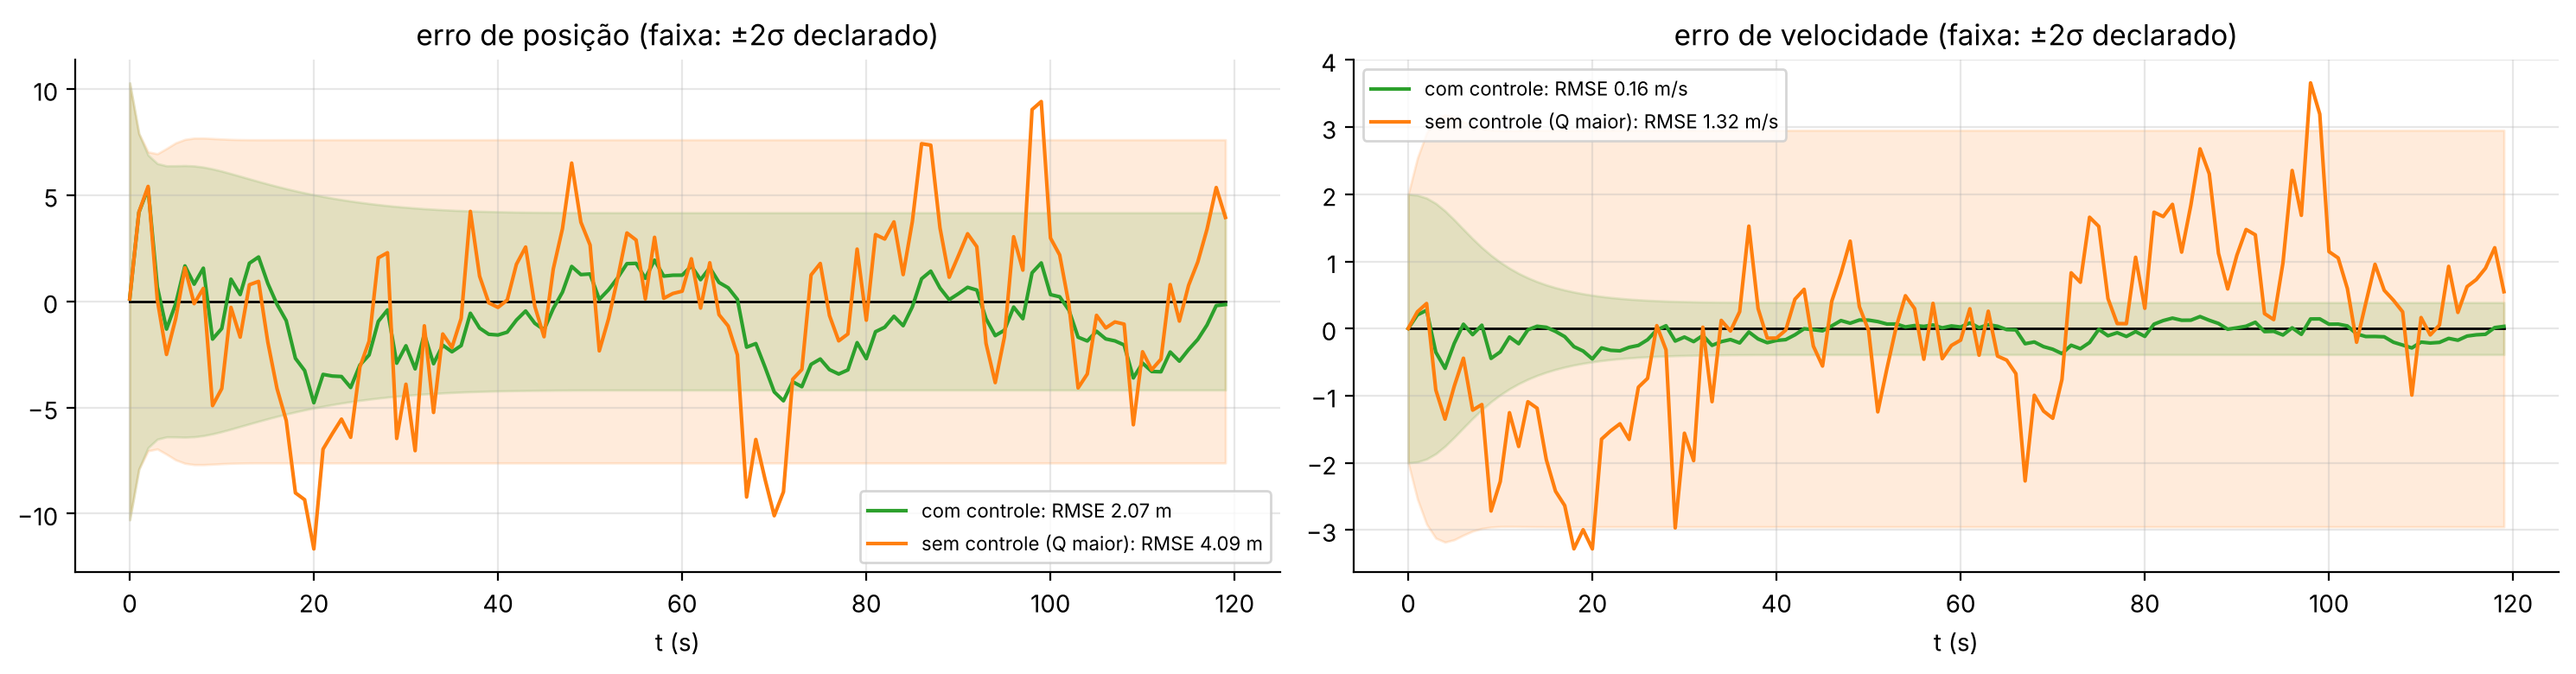

In [8]:
def kalman_trem(usa_controle, q_acel):
    Qf = q_acel**2 * (B @ B.T)
    m, P = np.array([0.0, 0.0]), np.diag([10.0**2, 1.0**2])
    ms, Ps = [], []
    for t in range(T):
        if t > 0:
            m = F @ m + (B.ravel() * u[t] if usa_controle else 0.0)
            P = F @ P @ F.T + Qf
        S = H2 @ P @ H2.T + R2; K = P @ H2.T @ np.linalg.inv(S)
        m = m + (K @ (np.array([s_med[t]]) - H2 @ m)).ravel(); P = P - K @ S @ K.T
        ms.append(m.copy()); Ps.append(P.copy())
    return np.array(ms), np.array(Ps)

m_c, P_c = kalman_trem(True, SIG_A)
m_s, P_s = kalman_trem(False, 0.8)

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for i, (nome, un) in enumerate([("posição", "m"), ("velocidade", "m/s")]):
    ax[i].plot(x_verd[:, i] - x_verd[:, i], "k", lw=1)
    for (mm, PP, txt, cor) in [(m_c, P_c, "com controle", "C2"), (m_s, P_s, "sem controle (Q maior)", "C1")]:
        e = mm[:, i] - x_verd[:, i]; sd = np.sqrt(PP[:, i, i])
        ax[i].plot(e, color=cor, label=f"{txt}: RMSE {np.sqrt(np.mean(e[10:]**2)):.2f} {un}")
        ax[i].fill_between(range(T), -2 * sd, 2 * sd, color=cor, alpha=.15)
    ax[i].set_title(f"erro de {nome} (faixa: ±2σ declarado)"); ax[i].set_xlabel("t (s)"); ax[i].legend(fontsize=8)
plt.tight_layout(); plt.show()

**O que observar.**

- **A velocidade nunca é medida**, e mesmo assim os dois filtros a estimam, pela correlação vista em 7.1.
- **O filtro com controle erra menos e declara menos incerteza.** Conhecer o comando do maquinista é informação que não precisa ser adivinhada pelas medidas.
- **O filtro sem controle** precisa de um $Q$ grande para não se perder nas acelerações e frenagens. Por isso confia menos no próprio modelo o tempo todo, inclusive quando o trem anda em velocidade constante: a faixa de 2σ dele é sempre mais larga, e os erros de velocidade se acumulam justamente durante as acelerações (perto de t = 20 s) e as frenagens (perto de t = 90 s).

---
# 8. Notas críticas

O artigo cumpre o que promete: uma porta de entrada intuitiva. Para usá-lo em sala, vale ter em mente:

1. **"Ótimo para sistemas lineares unidimensionais."** A restrição a uma dimensão não existe. O Kalman é o estimador de mínimo erro quadrático para sistemas lineares com ruídos gaussianos **em qualquer dimensão**. Sem a hipótese gaussiana, ele ainda é o melhor estimador **linear**.
2. **O produto de densidades precisa ser normalizado.** As eqs. (10)–(11) igualam o produto a uma gaussiana normalizada. A constante que falta (seção 4.2) é a verossimilhança da inovação, que tem papel central em outras partes da série.
3. **Falta a regra de Bayes.** O produto é apresentado como uma forma de "fundir" informação. A justificativa é *posterior* ∝ verossimilhança × *prior*, e a curva da medida é uma verossimilhança, não uma densidade da posição.
4. **A passagem para matrizes é por analogia.** O caso escalar não mostra as correlações fora da diagonal de $P$ (seção 7.1), nem o caso em que $H$ não é inversível. A receita de converter a predição para o domínio da medida e voltar só vale quando $H$ é inversível.
5. **Deslizes de notação.**
   - Na dedução de $P_{t|t-1}$, o erro antigo aparece como $x_{t-1}-\hat x_{t|t-1}$ onde deveria ser $\hat x_{t-1|t-1}$.
   - O texto diz que "a variância aumentou [ver (2)]", quando a equação da variância prevista é a (4).
   - Na comparação final, $K_t(z_t = H_t\hat x)$ deveria ser $K_t(z_t - H_t\hat x)$.

---
# 9. Exercícios

1. **Precisões.** Mostre algebricamente que a eq. (13) é equivalente a $1/\sigma^2=1/\sigma_1^2+1/\sigma_2^2$, e que a eq. (12) é a média ponderada pelas precisões.
2. **Três sensores.** Multiplique **três** gaussianas, a predição e duas medidas independentes de posição. Mostre que o resultado não depende da ordem e compare com a integração de sensores da Parte 1 do Pepé.
3. **A constante $Z$.** Para uma sequência de medidas do trem, some $\log Z_t$ ao longo do tempo para vários valores de $\sigma_a$ e desenhe a curva. Onde fica o máximo? Compare com o valor usado na simulação.
4. **Controle errado.** Simule um maquinista cujo comando registrado é 20% maior que o real. O que acontece com o filtro com controle? Como você detectaria o problema olhando as inovações?
5. **Duas dimensões, à mão.** Refaça a seção 7.1 com o *prior* **sem** correlação ($P^-$ diagonal). A velocidade ainda muda com a medida? Por quê?
6. **Trem com GPS e tempo de voo.** Acrescente uma segunda medida, de velocidade (como um GPS daria), com $R$ próprio. Monte $H$ $2\times2$ e $R$ bloco-diagonal, e compare os erros.